## Refining the comparative analysis for the Ross Sea compare manuscript 

October 2026   

I want to create a clean data file with the values we are comparing, and rejig the analysis so that it makes sense. 

We want to find a way to assess correlation that does not break any independence rules and tells us how comparable these different methods are. 

We want to look at: 

- Breeding pairs (midwinter)
- Breeding adults (BP x 2)  
- springtime abundance indices 
- chicks 


We want to ensure comparisons match units, so we would compare vhr individuals to breeding adults, and chicks to pairs.   

We also want to run a sensitivity analysis, looking how the Coulman Island 2025 chick count influences the correlation relationships. 

In [1]:
#Importing packages

import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mtick
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from scipy import stats
from scipy.optimize import minimize
from scipy.stats import chi2
from scipy.stats import pearsonr, spearmanr

from sklearn.metrics import mean_squared_error
from sklearn.utils import resample
from sklearn.preprocessing import StandardScaler
import statsmodels.formula.api as smf

import pymc as pm
import arviz as az



/home/rfo37/miniconda3/envs/era5_env/lib/python3.14/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


In [2]:
# Loading data 

INPUTPATH = "/mnt/c/Users/rfo37/OneDrive - University of Canterbury/Github/SAR_RossSea_compare/SAR_RossSea_compare/"

df_RossSea = pd.read_csv(os.path.join(INPUTPATH, "Data/RS_pops2425_combined.csv"))


#We attempted to use the Winterl density model on our VHR optical derived areas but this resulted in a large over estimate in colony size due to the estimated rho values so we chose to exclude these data from further analysis
#remove the VHR-rho

#creating categories
df_RossSea = df_RossSea.astype({
    'method': 'category',
    'type': 'category',
    'colony': 'category',
    'year': 'category', 
    'notes': 'category'
})

# Exclude a level from method 
noVHR_rho_df = df_RossSea[df_RossSea["method"] != "VHR-rho"]


In [3]:
#There were also three separate values calculated for Coulman Island 2025, on top of the iceberg, at the colony and combined, we want to exclude the non combined ones for now. 

condition_exclude = (noVHR_rho_df['notes'] == 'colony') | (noVHR_rho_df['notes'] == 'iceberg')

noVHR_rho_df = noVHR_rho_df[#condition_include & 
    ~condition_exclude]

print(noVHR_rho_df)


         colony site_id             type        date  month   day  year  \
0       Crozier    CROZ           adults  21/11/2024   11.0  21.0  2024   
1       Crozier    CROZ           adults  22/11/2025   11.0  22.0  2025   
2       Coulman    COUL           chicks  21/11/2024   11.0  21.0  2024   
3       Coulman    COUL           chicks   6/12/2025   12.0   6.0  2025   
4       Crozier    CROZ           chicks  21/11/2024   11.0  21.0  2024   
..          ...     ...              ...         ...    ...   ...   ...   
138    Franklin    FRAN  abundance index  24/10/2025   10.0  24.0  2025   
139       Roget    ROGE  abundance index  22/10/2025   10.0  22.0  2025   
140       Roget    ROGE  abundance index  11/10/2024   10.0  11.0  2024   
141  Washington    WASH  abundance index  27/10/2024   10.0  27.0  2024   
142  Washington    WASH  abundance index   1/11/2025   11.0   1.0  2025   

       DOY        lat         lon     count     count_se     method  \
0    325.0 -77.452742  169.2

### Now we want to refine the dataset to look at just the datapoints needed for the comparison between methods

In [4]:
# ---------------------------------------------------------
# Chick counts
# ---------------------------------------------------------

chicks = (
    noVHR_rho_df[
        (noVHR_rho_df['method'] == 'chicks') &
        (noVHR_rho_df['year'].isin([2024, 2025]))
    ][
        ['colony', 'year', 'count']
    ]
    .rename(columns={
        'count': 'chick_count'
    })
)

chicks

# ---------------------------------------------------------
# SAR-bp counts
# ---------------------------------------------------------

SAR_bp = (
    noVHR_rho_df[
        (noVHR_rho_df['method'] == 'SAR-bp') &
        (noVHR_rho_df['year'].isin([2024, 2025]))
    ][
        ['colony', 'year', 'count']
    ]
    .rename(columns={
        'count': 'sar-bp_count'
    })
)
SAR_bp


# ---------------------------------------------------------
# VHR-bayes counts
# ---------------------------------------------------------

VHR_bayes = (
    noVHR_rho_df[
        (noVHR_rho_df['method'] == 'VHR-bayes') &
        (noVHR_rho_df['year'].isin([2024, 2025]))
    ][
        ['colony', 'year', 'count']
    ]
    .rename(columns={
        'count': 'vhr-bayes_count'
    })
)
VHR_bayes




,colony,year,vhr-bayes_count
127,Beaufort,2024,293.27000
128,Beaufort,2025,273.90000
129,Colbeck,2024,23821.74000
130,Colbeck,2025,23618.61000
131,Coulman,2025,12409.81000
134,Coulman,2024,12045.81618
135,Crozier,2024,1332.22000
136,Crozier,2025,1715.35000
137,Franklin,2024,3172.53000
138,Franklin,2025,2998.27000


In [5]:
## Now we want to combine them
combined = (
    SAR_bp
    .merge(
        chicks,
        on=['colony', 'year'],
        how='left'
    )
)
combined

,colony,year,sar-bp_count,chick_count
0,Beaufort,2025,563.95,NaN
1,Colbeck,2025,21418.41,NaN
2,Coulman,2025,16088.12,6686.0
3,Coulman,2024,16376.19,21242.0
4,Crozier,2025,1990.66,2782.0
5,Crozier,2024,2349.79,2773.0
6,Franklin,2025,4318.43,NaN
7,Franklin,2024,5029.93,NaN
8,Roget,2025,7252.01,7736.0
9,Roget,2024,5261.45,7397.0


In [8]:
## Now we want to combine them again
combined_2 = (
    combined
    .merge(
        VHR_bayes,
        on=['colony', 'year'],
        how='left'
    )
)
combined_2

#Adding new column (breeding adults = bp x 2)
combined_2["breeding_adults"] = combined_2["sar-bp_count"] * 2


combined_2.to_csv(os.path.join(INPUTPATH, "Data/compare_df.csv"), index=False)
print(combined_2)


        colony  year  sar-bp_count  chick_count  vhr-bayes_count  \
0     Beaufort  2025        563.95          NaN        273.90000   
1      Colbeck  2025      21418.41          NaN      23618.61000   
2      Coulman  2025      16088.12       6686.0      12409.81000   
3      Coulman  2024      16376.19      21242.0      12045.81618   
4      Crozier  2025       1990.66       2782.0       1715.35000   
5      Crozier  2024       2349.79       2773.0       1332.22000   
6     Franklin  2025       4318.43          NaN       2998.27000   
7     Franklin  2024       5029.93          NaN       3172.53000   
8        Roget  2025       7252.01       7736.0       4049.60000   
9        Roget  2024       5261.45       7397.0       4382.11000   
10  Washington  2025      11367.90      14297.0       6819.64000   
11  Washington  2024      10341.24      13803.0       7458.19000   

    breeding_adults  
0           1127.90  
1          42836.82  
2          32176.24  
3          32752.38  
4    

### Ok the data is saved, now we move forward using the combined_2 dataset. 


## We also want to make a simple barplot with all three (four datatypes) different methods 

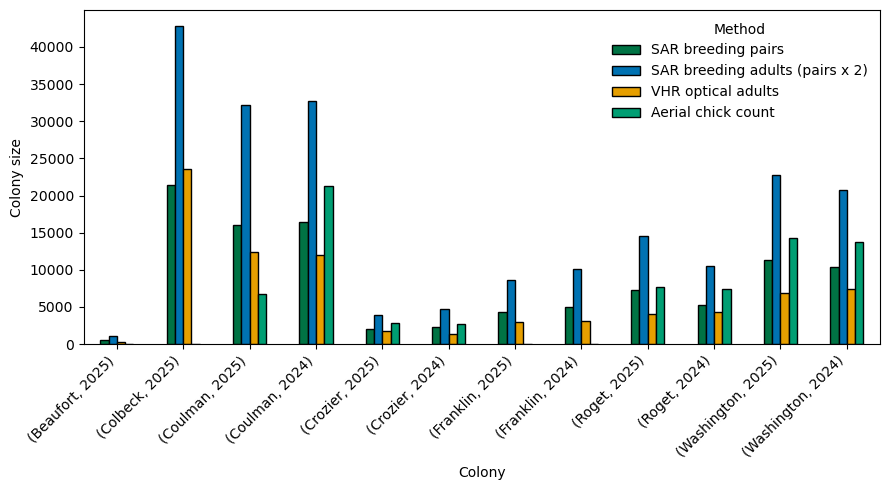

In [10]:
import matplotlib.pyplot as plt

# pick the columns to plot and give them readable legend names
plot_df = combined_2[["colony", "year", "sar-bp_count", "breeding_adults", "vhr-bayes_count", "chick_count"]]
plot_df = plot_df.rename(columns={
    "sar-bp_count": "SAR breeding pairs",
    "breeding_adults": "SAR breeding adults (pairs x 2)",
    "vhr-bayes_count": "VHR optical adults",
    "chick_count": "Aerial chick count",
})

#plot_df = plot_df.join(combined_2["year"])
plot_df = plot_df.set_index(["colony", "year"])

ax = plot_df.plot.bar(color=["#007344", "#0072B2", "#E69F00", "#009E73"],
                      edgecolor="black", figsize=(9, 5))
ax.set_xlabel("Colony")
ax.set_ylabel("Colony size")
ax.legend(title="Method", frameon=False)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
#plt.savefig("colony_sizes.png", dpi=300)
plt.show()

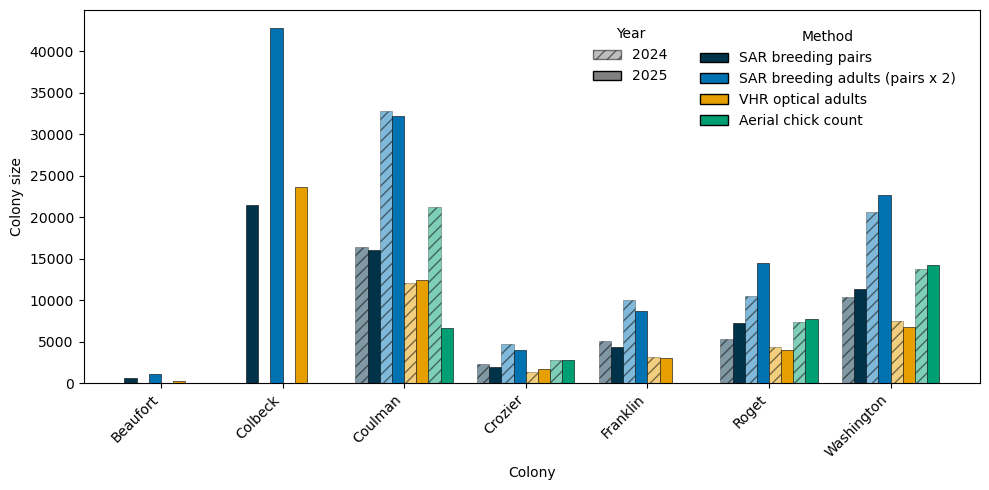

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# column name: (legend label, colour)
methods = {
    "sar-bp_count": ("SAR breeding pairs","#003349"),
    "breeding_adults": ("SAR breeding adults (pairs x 2)", "#0072B2"),
    "vhr-bayes_count": ("VHR optical adults", "#E69F00"),
    "chick_count": ("Aerial chick count", "#009E73"),
}

def plot_by_year(df, log_scale=False, outfile="colony_sizes.png"):
    colonies = sorted(df["colony"].unique())
    years = sorted(df["year"].unique())
    first_year = years[0]

    x = np.arange(len(colonies))              # one position per colony
    n_bars = len(methods) * len(years)        # 3 methods x 2 years = 6 bars
    width = 0.8 / n_bars

    fig, ax = plt.subplots(figsize=(10, 5))
    bar_number = 0
    for col, (label, colour) in methods.items():
        for yr in years:
            # this year's value for each colony (NaN if missing)
            values = (df[df["year"] == yr]
                      .set_index("colony")[col]
                      .reindex(colonies))
            # first year hatched lighter, second year solid
            if yr == first_year:
                alpha, hatch = 0.5, "///"
            else:
                alpha, hatch =  1.0, ""
            offset = (bar_number - (n_bars - 1) / 2) * width
            ax.bar(x + offset, values, width=width, color=colour,
                   alpha=alpha, hatch=hatch, edgecolor="black", linewidth=0.4)
            bar_number += 1

    ax.set_xticks(x)
    ax.set_xticklabels(colonies, rotation=45, ha="right")
    ax.set_xlabel("Colony")
    if log_scale:
        ax.set_yscale("log")
        ax.set_ylabel("Colony size (log scale)")
    else:
        ax.set_ylabel("Colony size")

    # two legends: colour = method, hatching = year
    method_key = [Patch(facecolor=c, edgecolor="black", label=l)
                  for l, c in methods.values()]
    year_key = [Patch(facecolor="grey", edgecolor="black", alpha=0.5,
                      hatch="///", label=str(years[0])),
                      Patch(facecolor="grey", edgecolor="black", label=str(years[1]))
                ]
    leg1 = ax.legend(handles=method_key, title="Method", ncol=1,
                     loc="lower center", bbox_to_anchor=(0.83, 0.65), frameon=False)
    ax.add_artist(leg1)
    leg2 = ax.legend(handles=year_key, title="Year", loc="lower center",
                     bbox_to_anchor=(0.61, 0.77), frameon=False)

    fig.tight_layout()
    fig.savefig(outfile, dpi=600, bbox_inches="tight",
                bbox_extra_artists=[leg1, leg2])
    plt.show()

from pathlib import Path
results_dir = Path(INPUTPATH) / "Results"

# raw counts, then log scale
plot_by_year(combined_2, log_scale=False, outfile= results_dir / "colony_sizes_raw.png")

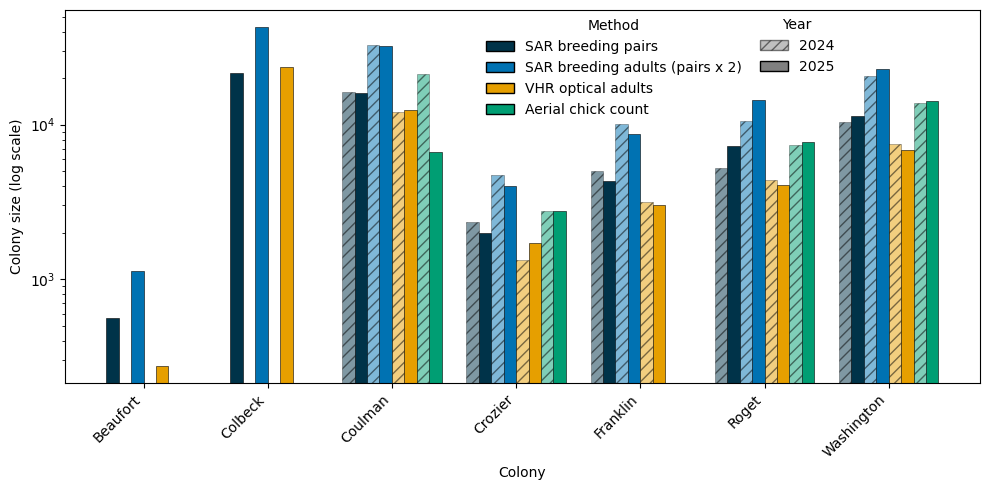

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# column name: (legend label, colour)
methods = {
    "sar-bp_count": ("SAR breeding pairs","#003349"),
    "breeding_adults": ("SAR breeding adults (pairs x 2)", "#0072B2"),
    "vhr-bayes_count": ("VHR optical adults", "#E69F00"),
    "chick_count": ("Aerial chick count", "#009E73"),
}

def plot_by_year(df, log_scale=False, outfile="colony_sizes.png"):
    colonies = sorted(df["colony"].unique())
    years = sorted(df["year"].unique())
    first_year = years[0]

    x = np.arange(len(colonies))              # one position per colony
    n_bars = len(methods) * len(years)        # 3 methods x 2 years = 6 bars
    width = 0.8 / n_bars

    fig, ax = plt.subplots(figsize=(10, 5))
    bar_number = 0
    for col, (label, colour) in methods.items():
        for yr in years:
            # this year's value for each colony (NaN if missing)
            values = (df[df["year"] == yr]
                      .set_index("colony")[col]
                      .reindex(colonies))
            # first year hatched lighter, second year solid
            if yr == first_year:
                alpha, hatch = 0.5, "///"
            else:
                alpha, hatch =  1.0, ""
            offset = (bar_number - (n_bars - 1) / 2) * width
            ax.bar(x + offset, values, width=width, color=colour,
                   alpha=alpha, hatch=hatch, edgecolor="black", linewidth=0.4)
            bar_number += 1

    ax.set_xticks(x)
    ax.set_xticklabels(colonies, rotation=45, ha="right")
    ax.set_xlabel("Colony")
    if log_scale:
        ax.set_yscale("log")
        ax.set_ylabel("Colony size (log scale)")
    else:
        ax.set_ylabel("Colony size")

    # two legends: colour = method, hatching = year
    method_key = [Patch(facecolor=c, edgecolor="black", label=l)
                  for l, c in methods.values()]
    year_key = [Patch(facecolor="grey", edgecolor="black", alpha=0.5,
                      hatch="///", label=str(years[0])),
                      Patch(facecolor="grey", edgecolor="black", label=str(years[1]))
                ]
    leg1 = ax.legend(handles=method_key, title="Method", ncol=1,
                     loc="lower center", bbox_to_anchor=(0.6, 0.68), frameon=False)
    ax.add_artist(leg1)
    leg2 = ax.legend(handles=year_key, title="Year", loc="lower center",
                     bbox_to_anchor=(0.8, 0.795), frameon=False)

    fig.tight_layout()
    fig.savefig(outfile, dpi=600, bbox_inches="tight",
                bbox_extra_artists=[leg1, leg2])
    plt.show()

from pathlib import Path
results_dir = Path(INPUTPATH) / "Results"

#  log scale
plot_by_year(combined_2, log_scale=True, outfile= results_dir / "colony_sizes_log.png")

____

## Now we want to assess relationships between the results 

First we will analyse the full dataset, looking at correlations (taking mean of two years to avoid independence assumption issues) and calculating log-ratio and mean absolute percent difference.   


We will then also look at a reduced dataset, removing Coulman chicks 2025 from the mean to see if the relationship improved without that outlier.   


We will also try to redo the plots from the four panel plot in the other script, including the mean point, shaded possibly, and a both incl and not incl chickc oculman in the text. 

In [13]:
#Now I want to assess relationships between variables 

import numpy as np
import pandas as pd
from pathlib import Path
from itertools import combinations
from scipy import stats
import pymc as pm
import arviz as az


# ---------------------------------------------------------------------------
# Simple, assumption-safe check: average each colony across years,
#     then correlate on the log scale (one independent point per colony)
# ---------------------------------------------------------------------------

# log of each count 
combined_2["log_BP"] = np.log(combined_2["sar-bp_count"])
combined_2["log_BA"] = np.log(combined_2["breeding_adults"])
combined_2["log_vhr"] = np.log(combined_2["vhr-bayes_count"])
combined_2["log_chick"] = np.log(combined_2["chick_count"])

log_cols = ["log_BP", "log_BA", "log_vhr", "log_chick"]
print(combined_2)

        colony  year  sar-bp_count  chick_count  vhr-bayes_count  \
0     Beaufort  2025        563.95          NaN        273.90000   
1      Colbeck  2025      21418.41          NaN      23618.61000   
2      Coulman  2025      16088.12       6686.0      12409.81000   
3      Coulman  2024      16376.19      21242.0      12045.81618   
4      Crozier  2025       1990.66       2782.0       1715.35000   
5      Crozier  2024       2349.79       2773.0       1332.22000   
6     Franklin  2025       4318.43          NaN       2998.27000   
7     Franklin  2024       5029.93          NaN       3172.53000   
8        Roget  2025       7252.01       7736.0       4049.60000   
9        Roget  2024       5261.45       7397.0       4382.11000   
10  Washington  2025      11367.90      14297.0       6819.64000   
11  Washington  2024      10341.24      13803.0       7458.19000   

    breeding_adults    log_BP     log_BA    log_vhr  log_chick  
0           1127.90  6.334966   7.028113   5.61276

In [16]:
colony_means = combined_2.groupby("colony")[log_cols].mean()

results = []
for a, b in combinations(log_cols, 2):        # all pairs
    pair = colony_means[[a, b]].dropna()       # colonies with both methods
    pearson = stats.pearsonr(pair[a], pair[b])
    ci = pearson.confidence_interval()
    rho, p_rho = stats.spearmanr(pair[a], pair[b])
    results.append({
        "pair": f"{a} vs {b}",
        "n_colonies": len(pair),
        "pearson_r": pearson.statistic,
        "ci_low": ci.low, "ci_high": ci.high,
        "p": pearson.pvalue,
        "spearman_rho": rho, "p_spearman": p_rho,
    })

print(pd.DataFrame(results).round(5))

                   pair  n_colonies  pearson_r   ci_low  ci_high        p  \
0      log_BP vs log_BA           7    1.00000  1.00000  1.00000  0.00000   
1     log_BP vs log_vhr           7    0.99536  0.96751  0.99934  0.00000   
2   log_BP vs log_chick           4    0.95768 -0.04282  0.99914  0.04232   
3     log_BA vs log_vhr           7    0.99536  0.96751  0.99934  0.00000   
4   log_BA vs log_chick           4    0.95768 -0.04282  0.99914  0.04232   
5  log_vhr vs log_chick           4    0.93796 -0.23474  0.99873  0.06204   

   spearman_rho  p_spearman  
0           1.0         0.0  
1           1.0         0.0  
2           0.8         0.2  
3           1.0         0.0  
4           0.8         0.2  
5           0.8         0.2  


In [17]:
print(colony_means)

              log_BP     log_BA    log_vhr  log_chick
colony                                               
Beaufort    6.334966   7.028113   5.612763        NaN
Colbeck     9.972006  10.665153  10.069790        NaN
Coulman     9.694710  10.387857   9.411358   9.385753
Crozier     7.679151   8.372299   7.320987   7.929305
Franklin    8.446904   9.140051   8.034038        NaN
Roget       8.728598   9.421745   8.345830   8.931235
Washington  9.291222   9.984369   8.872315   9.550223


___

### Ok next up, we want to look at the log-ratios to see how each compares to each other

In [18]:
def colony_averaged_correlations(df):
    means = df.groupby("colony")[log_cols].mean()  # skips NA
    rows = []
    for a, b in combinations (log_cols, 2):
        sub = means[[a, b]].dropna()
        n = len(sub)
        if n < 3:
            rows.append(dict(pair=f"{a} vs {b}", n_colonies=n))
            continue
        r, p = stats.pearsonr(sub[a], sub[b])
        rho, p_rho = stats.spearmanr(sub[a], sub[b])
        # Fisher z 95% CI (needs n >= 4)
        if n >= 4:
            z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
            lo, hi = np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se)
        else:
            lo = hi = np.nan
        rows.append(dict(pair=f"{a} vs {b}", n_colonies=n,
                         pearson_r=r, ci_low=lo, ci_high=hi, p=p,
                         spearman_rho=rho, p_spearman=p_rho))
    return pd.DataFrame(rows)


def summarise_correlations(idata, prior):
    post = idata.posterior["colony_corr"]
    prior = prior.prior["colony_corr"]
    rows = []
    for a, b in combinations(log_cos,2):
        d = post.sel(method_1=a, method_2=b).values.ravel()
        p = prior.sel(method_1=a, method_2=b).values.ravel()
        lo, hi = np.percentile(d, [2.5, 97.5])
        p_lo, p_hi = np.percentile(p, [2.5, 97.5])
        rows.append(dict(pair=f"{a} vs {b}",
                         posterior_median=np.median(d),
                         ci95_low=lo, ci95_high=hi,
                         prob_positive=(d > 0).mean(),
                         prior_ci95_width=p_hi - p_lo,
                         posterior_ci95_width=hi - lo))
    return pd.DataFrame(rows)

print("\nColony-averaged correlations (log scale, one point per colony)")
print(colony_averaged_correlations(combined_2).round(5).to_string(index=False))



Colony-averaged correlations (log scale, one point per colony)
                pair  n_colonies  pearson_r   ci_low  ci_high       p  spearman_rho  p_spearman
    log_BP vs log_BA           7    1.00000  1.00000  1.00000 0.00000           1.0         0.0
   log_BP vs log_vhr           7    0.99536  0.96751  0.99934 0.00000           1.0         0.0
 log_BP vs log_chick           4    0.95768 -0.04286  0.99914 0.04232           0.8         0.2
   log_BA vs log_vhr           7    0.99536  0.96751  0.99934 0.00000           1.0         0.0
 log_BA vs log_chick           4    0.95768 -0.04286  0.99914 0.04232           0.8         0.2
log_vhr vs log_chick           4    0.93796 -0.23477  0.99873 0.06204           0.8         0.2


In [20]:
# log ratio per colony, averaged across years (one value per colony)
combined_2["lr_vhr_BA"] = combined_2["log_vhr"] - combined_2["log_BA"]  #we are comparing breeding adults to vhr individuals 
combined_2["lr_chick_pair"] = np.log(combined_2["chick_count"] / combined_2["sar-bp_count"]) #comparing chicks to breeding pairs 
combined_2["lr_chick_vhr"] = np.log(combined_2["chick_count"] / combined_2["vhr-bayes_count"]) #comparing chicks to vhr individuals

for col, name in [("lr_vhr_BA", "VHR adults per SAR breeding adult"),
                  ("lr_chick_pair", "Chicks per SAR breeding pair"), 
                  ("lr_chick_vhr", "Chicks per VHR adult index")]:
    per_colony = combined_2.groupby("colony")[col].mean().dropna()
    n = len(per_colony)
    m, sd = per_colony.mean(), per_colony.std(ddof=1)
    t = stats.t.ppf(0.975, n - 1)
    print(f"\n{name} (n = {n} colonies)")
    print(f"  mean ratio: {np.exp(m):.3f}  "
          f"(95% CI {np.exp(m - t * sd / np.sqrt(n)):.3f} to {np.exp(m + t * sd / np.sqrt(n)):.3f})")
    print(f"  limits of agreement: {np.exp(m - 1.96 * sd):.3f} to {np.exp(m + 1.96 * sd):.3f}")


VHR adults per SAR breeding adult (n = 7 colonies)
  mean ratio: 0.351  (95% CI 0.280 to 0.439)
  limits of agreement: 0.218 to 0.564

Chicks per SAR breeding pair (n = 4 colonies)
  mean ratio: 1.106  (95% CI 0.715 to 1.711)
  limits of agreement: 0.646 to 1.893

Chicks per VHR adult index (n = 4 colonies)
  mean ratio: 1.586  (95% CI 0.943 to 2.670)
  limits of agreement: 0.836 to 3.012


## I also want to test removing the Coulman 2025 observation as it was caused by the iceberg. 
### Is it that single obs that make the chick correlations so low? 



In [22]:
# Removing Coulman 2025 to test importance of that point

# drop Coulman 2025 chick count (iceberg mortality event); keep SAR and VHR values
coulman_2025 = (
    combined_2["colony"].str.contains("Coulman", case=False)
    & (combined_2["year"] == 2025)
)
print(combined_2.loc[coulman_2025])  # check exactly one row matches

# new dataset with the Coulman 2025 chick count removed; SAR and VHR values kept
combined_2_noC25 = combined_2.copy()
combined_2_noC25.loc[coulman_2025, "chick_count"] = np.nan

# if log columns already exist, blank the chick log as well
if "log_chick" in combined_2_noC25.columns:
    combined_2_noC25.loc[coulman_2025, "log_chick"] = np.nan


# ---------------------------------------------------------------------------
# Simple, assumption-safe check: average each colony across years,
#     then correlate on the log scale (one independent point per colony)
# ---------------------------------------------------------------------------

# log of each count 
combined_2_noC25["log_BP"] = np.log(combined_2_noC25["sar-bp_count"])
combined_2_noC25["log_BA"] = np.log(combined_2_noC25["breeding_adults"])
combined_2_noC25["log_vhr"] = np.log(combined_2_noC25["vhr-bayes_count"])
combined_2_noC25["log_chick"] = np.log(combined_2_noC25["chick_count"])

log_cols = ["log_BP", "log_BA", "log_vhr", "log_chick"]
print(combined_2_noC25)

    colony  year  sar-bp_count  chick_count  vhr-bayes_count  breeding_adults  \
2  Coulman  2025      16088.12       6686.0         12409.81         32176.24   

     log_BP     log_BA   log_vhr  log_chick  lr_vhr_BA  lr_chick_pair  \
2  9.685836  10.378984  9.426243   8.807771  -0.952741      -0.878065   

   lr_chick_vhr  
2     -0.618472  
        colony  year  sar-bp_count  chick_count  vhr-bayes_count  \
0     Beaufort  2025        563.95          NaN        273.90000   
1      Colbeck  2025      21418.41          NaN      23618.61000   
2      Coulman  2025      16088.12          NaN      12409.81000   
3      Coulman  2024      16376.19      21242.0      12045.81618   
4      Crozier  2025       1990.66       2782.0       1715.35000   
5      Crozier  2024       2349.79       2773.0       1332.22000   
6     Franklin  2025       4318.43          NaN       2998.27000   
7     Franklin  2024       5029.93          NaN       3172.53000   
8        Roget  2025       7252.01       7

In [ ]:
colony_means = combined_2_noC25.groupby("colony")[log_cols].mean()

results = []
for a, b in combinations(log_cols, 2):        # all pairs
    pair = colony_means[[a, b]].dropna()       # colonies with both methods
    pearson = stats.pearsonr(pair[a], pair[b])
    ci = pearson.confidence_interval()
    rho, p_rho = stats.spearmanr(pair[a], pair[b])
    results.append({
        "pair": f"{a} vs {b}",
        "n_colonies": len(pair),
        "pearson_r": pearson.statistic,
        "ci_low": ci.low, "ci_high": ci.high,
        "p": pearson.pvalue,
        "spearman_rho": rho, "p_spearman": p_rho,
    })

print(pd.DataFrame(results).round(5))

                   pair  n_colonies  pearson_r   ci_low  ci_high        p  \
0      log_BP vs log_BA           7    1.00000  1.00000  1.00000  0.00000   
1     log_BP vs log_vhr           7    0.99536  0.96751  0.99934  0.00000   
2   log_BP vs log_chick           4    0.99951  0.97551  0.99999  0.00049   
3     log_BA vs log_vhr           7    0.99536  0.96751  0.99934  0.00000   
4   log_BA vs log_chick           4    0.99951  0.97551  0.99999  0.00049   
5  log_vhr vs log_chick           4    0.99824  0.91477  0.99996  0.00176   

   spearman_rho  p_spearman  
0           1.0         0.0  
1           1.0         0.0  
2           1.0         0.0  
3           1.0         0.0  
4           1.0         0.0  
5           1.0         0.0  


In [25]:
print(colony_means)

              log_BP     log_BA    log_vhr  log_chick
colony                                               
Beaufort    6.334966   7.028113   5.612763        NaN
Colbeck     9.972006  10.665153  10.069790        NaN
Coulman     9.694710  10.387857   9.411358   9.963736
Crozier     7.679151   8.372299   7.320987   7.929305
Franklin    8.446904   9.140051   8.034038        NaN
Roget       8.728598   9.421745   8.345830   8.931235
Washington  9.291222   9.984369   8.872315   9.550223


In [26]:
def colony_averaged_correlations(df):
    means = df.groupby("colony")[log_cols].mean()  # skips NA
    rows = []
    for a, b in combinations (log_cols, 2):
        sub = means[[a, b]].dropna()
        n = len(sub)
        if n < 3:
            rows.append(dict(pair=f"{a} vs {b}", n_colonies=n))
            continue
        r, p = stats.pearsonr(sub[a], sub[b])
        rho, p_rho = stats.spearmanr(sub[a], sub[b])
        # Fisher z 95% CI (needs n >= 4)
        if n >= 4:
            z, se = np.arctanh(r), 1 / np.sqrt(n - 3)
            lo, hi = np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se)
        else:
            lo = hi = np.nan
        rows.append(dict(pair=f"{a} vs {b}", n_colonies=n,
                         pearson_r=r, ci_low=lo, ci_high=hi, p=p,
                         spearman_rho=rho, p_spearman=p_rho))
    return pd.DataFrame(rows)


def summarise_correlations(idata, prior):
    post = idata.posterior["colony_corr"]
    prior = prior.prior["colony_corr"]
    rows = []
    for a, b in combinations(log_cos,2):
        d = post.sel(method_1=a, method_2=b).values.ravel()
        p = prior.sel(method_1=a, method_2=b).values.ravel()
        lo, hi = np.percentile(d, [2.5, 97.5])
        p_lo, p_hi = np.percentile(p, [2.5, 97.5])
        rows.append(dict(pair=f"{a} vs {b}",
                         posterior_median=np.median(d),
                         ci95_low=lo, ci95_high=hi,
                         prob_positive=(d > 0).mean(),
                         prior_ci95_width=p_hi - p_lo,
                         posterior_ci95_width=hi - lo))
    return pd.DataFrame(rows)

print("\nColony-averaged correlations (log scale, one point per colony, removed Coulman chicks 2025)")
print(colony_averaged_correlations(combined_2).round(6).to_string(index=False))



Colony-averaged correlations (log scale, one point per colony, removed Coulman chicks 2025)
                pair  n_colonies  pearson_r    ci_low  ci_high        p  spearman_rho  p_spearman
    log_BP vs log_BA           7   1.000000  1.000000 1.000000 0.000000           1.0         0.0
   log_BP vs log_vhr           7   0.995358  0.967507 0.999345 0.000003           1.0         0.0
 log_BP vs log_chick           4   0.957679 -0.042859 0.999143 0.042321           0.8         0.2
   log_BA vs log_vhr           7   0.995358  0.967507 0.999345 0.000003           1.0         0.0
 log_BA vs log_chick           4   0.957679 -0.042859 0.999143 0.042321           0.8         0.2
log_vhr vs log_chick           4   0.937955 -0.234774 0.998730 0.062045           0.8         0.2


In [27]:
# log ratio per colony, averaged across years (one value per colony)
combined_2_noC25["lr_vhr_sar"] = combined_2_noC25["log_vhr"] - combined_2_noC25["log_BA"] #comparing vhr individuals to breeding adults
combined_2_noC25["lr_chick_pair"] = np.log(combined_2_noC25["chick_count"] / combined_2_noC25["sar-bp_count"]) #comparing chicks to breeding pairs
combined_2_noC25["lr_chick_vhr"] = np.log(combined_2_noC25["chick_count"] / combined_2_noC25["vhr-bayes_count"]) #comparing chicks to vhr individuals

for col, name in [("lr_vhr_sar", "VHR adults per SAR breeding adult"),
                  ("lr_chick_pair", "Chicks per SAR breeding pair"), 
                  ("lr_chick_vhr", "Chicks per VHR adult index")]:
    per_colony = combined_2_noC25.groupby("colony")[col].mean().dropna()
    n = len(per_colony)
    m, sd = per_colony.mean(), per_colony.std(ddof=1)
    t = stats.t.ppf(0.975, n - 1)
    print(f"\n{name} (n = {n} colonies)")
    print(f"  mean ratio: {np.exp(m):.5f}  "
          f"(95% CI {np.exp(m - t * sd / np.sqrt(n)):.5f} to {np.exp(m + t * sd / np.sqrt(n)):.5f})")
    print(f"  limits of agreement: {np.exp(m - 1.96 * sd):.5f} to {np.exp(m + 1.96 * sd):.5f}")


VHR adults per SAR breeding adult (n = 7 colonies)
  mean ratio: 0.35081  (95% CI 0.28030 to 0.43906)
  limits of agreement: 0.21805 to 0.56442

Chicks per SAR breeding pair (n = 4 colonies)
  mean ratio: 1.27505  (95% CI 1.22091 to 1.33159)
  limits of agreement: 1.20870 to 1.34505

Chicks per VHR adult index (n = 4 colonies)
  mean ratio: 1.83992  (95% CI 1.70337 to 1.98742)
  limits of agreement: 1.67320 to 2.02325


In [35]:
# Method comparison: fold difference, consistency, and tracking
# all on colony means of log counts (one value per colony)

comparisons = [
    ("breeding_adults", "vhr-bayes_count", "SAR breeding adults vs VHR adults"),
    ("sar-bp_count", "chick_count", "SAR breeding pairs vs chicks"),
    ("vhr-bayes_count", "chick_count", "VHR adults vs chicks"),
]

def compare_methods(df, label):
    print(f"\n===== {label} =====")

    for a, b, name in comparisons:
        d = df[["colony", a, b]].dropna()
        d = d[(d[a] > 0) & (d[b] > 0)]

        d["log_a"] = np.log(d[a])
        d["log_b"] = np.log(d[b])
        per_colony = d.groupby("colony")[["log_a", "log_b"]].mean()
        per_colony["log_ratio"] = per_colony["log_a"] - per_colony["log_b"]

        n = len(per_colony)
        if n < 3:
            print(f"\n{name}: only {n} colonies, skipping")
            continue

        lr = per_colony["log_ratio"]
        m, sd = lr.mean(), lr.std(ddof=1)
        t = stats.t.ppf(0.975, n - 1)
        se = sd / np.sqrt(n)
        r, p = stats.pearsonr(per_colony["log_a"], per_colony["log_b"])

        print(f"\n{name} (n = {n} colonies)")
        print(f"  fold difference: {np.exp(m):.2f}x  "
              f"(95% CI {np.exp(m - t * se):.2f}x to {np.exp(m + t * se):.2f}x)")
        print(f"  colony range: {np.exp(lr.min()):.2f}x to {np.exp(lr.max()):.2f}x  "
              f"(geometric SD {np.exp(sd):.2f})")
        print(f"  log-scale Pearson r = {r:.5f} (p = {p:.6f})")
        print(np.exp(lr).round(5).rename("fold").to_string())

compare_methods(combined_2_noC25, "Coulman 2025 excluded")
compare_methods(combined_2, "Coulman 2025 included")


===== Coulman 2025 excluded =====

SAR breeding adults vs VHR adults (n = 7 colonies)
  fold difference: 2.85x  (95% CI 2.28x to 3.57x)
  colony range: 1.81x to 4.12x  (geometric SD 1.27)
  log-scale Pearson r = 0.99536 (p = 0.000003)
colony
Beaufort      4.11793
Colbeck       1.81369
Coulman       2.65515
Crozier       2.86140
Franklin      3.02229
Roget         2.93268
Washington    3.04060

SAR breeding pairs vs chicks (n = 4 colonies)
  fold difference: 0.78x  (95% CI 0.75x to 0.82x)
  colony range: 0.77x to 0.82x  (geometric SD 1.03)
  log-scale Pearson r = 0.99956 (p = 0.000445)
colony
Coulman       0.77093
Crozier       0.77868
Roget         0.81657
Washington    0.77182

VHR adults vs chicks (n = 4 colonies)
  fold difference: 0.54x  (95% CI 0.50x to 0.59x)
  colony range: 0.51x to 0.57x  (geometric SD 1.05)
  log-scale Pearson r = 0.99850 (p = 0.001497)
colony
Coulman       0.56708
Crozier       0.54427
Roget         0.55688
Washington    0.50768

===== Coulman 2025 included 